# Week 11: DBSCAN and Hierarchical Agglomerative Clustering
**Capstone project:** Predicting Health Risk and Diabetes Status from Lifestyle and Survey Data | Komal Misra

Week 10's k-means needed the number of clusters in advance and assumed round, similar-sized clusters. This week's two methods drop both assumptions:
- **Hierarchical agglomerative clustering (HAC)** starts with every point in its own cluster and repeatedly merges the closest pair. The full merge history, drawn as a **dendrogram**, can be cut at any height to get any number of clusters.
- **DBSCAN** defines clusters as dense regions separated by sparse ones. It finds the number of clusters on its own, allows any cluster shape, and labels isolated points as **noise** instead of forcing them into a cluster.

As in Week 10, the outcomes (diabetes in BRFSS, `disease_risk` in the Lifestyle data) are held out and used only afterwards to judge whether clusters mean anything.

**Sections**
1. Setup and data
2. HAC by hand: the cookie example
3. The four linkage methods
4. Linkage methods on shaped data
5. DBSCAN by hand: core, border and noise points
6. How ε and MinPts change the result
7. DBSCAN on the project data
8. HAC on the project data
9. Summary

## 1. Setup and data

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_moons, make_blobs
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet, set_link_color_palette
from scipy.spatial.distance import pdist

warnings.filterwarnings('ignore')
SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})
BLUE, ORANGE, GREEN, VIOLET, RED, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#6250d6', '#e34948', '#8a8984'
PAL = [BLUE, ORANGE, GREEN, VIOLET, '#eda100', '#e87ba4', '#008300', RED]
set_link_color_palette([BLUE, ORANGE, GREEN, VIOLET])

In [2]:
brfss = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')
life = pd.read_csv('health_lifestyle_dataset.csv')
brfss['diabetes'] = (brfss['Diabetes_012'] > 0).astype(int)

XB_all, yB_all = brfss.drop(columns=['Diabetes_012', 'diabetes']), brfss['diabetes']
B, _, yB, _ = train_test_split(XB_all, yB_all, train_size=50_000, stratify=yB_all, random_state=SEED)
B, yB = B.reset_index(drop=True), yB.reset_index(drop=True)
la = life.drop(columns=['id']).assign(gender=lambda d: (d.gender == 'Male').astype(int)).sample(50_000, random_state=SEED).reset_index(drop=True)
A, riskA = la.drop(columns=['disease_risk']), la['disease_risk']
print('Dataset B:', B.shape, '| Dataset A:', A.shape)

Dataset B: (50000, 21) | Dataset A: (50000, 14)


Both methods are expensive on large data. HAC needs the distance between every pair of points (5,000 points means about 12.5 million pairs; 50,000 would mean 1.25 billion), so I work with **5,000-row random samples** of the standardized data. I also build a **column-shuffled copy** of the Lifestyle data as a no-structure baseline, as in Week 10.

To use the same samples as the Milestone 2 analysis, the random generator is advanced exactly as that script did: shuffling the columns for both null datasets, then twelve split-half draws for Week 10's reproducibility check.

In [3]:
rng = np.random.default_rng(SEED)
def permute(df):
    return pd.DataFrame({c: rng.permutation(df[c].values) for c in df.columns})
A_null, B_null = permute(A), permute(B)
for _ in range(12):                      # Week 10 split-half draws (4 datasets x k = 2, 3, 4)
    rng.permutation(50_000)

ZA, ZB, ZA_null = (StandardScaler().fit_transform(d) for d in (A, B, A_null))
n = 5000
idxA = rng.choice(50_000, n, replace=False); _ = rng.choice(50_000, n, replace=False)
idxA_null = rng.choice(50_000, n, replace=False); idxB = rng.choice(50_000, n, replace=False)
S = {'A': ZA[idxA], 'B': ZB[idxB], 'A_null': ZA_null[idxA_null]}
yS = yB.values[idxB]
print({k: v.shape for k, v in S.items()}, f'| diabetes in BRFSS sample: {yS.mean():.1%}')

{'A': (5000, 14), 'B': (5000, 21), 'A_null': (5000, 14)} | diabetes in BRFSS sample: 16.3%


## 2. HAC by hand: the cookie example
Five cookies with diameters 4, 4.5, 6, 7 and 11 cm. With **single linkage**, the distance between two clusters is the distance between their *closest* members. Each step merges the closest pair of clusters:

In [4]:
cookies = [4, 4.5, 6, 7, 11]
clusters = [[c] for c in cookies]
def single(a, b): return min(abs(x - y) for x in a for y in b)

print('Start:   ', clusters)
step = 1
while len(clusters) > 1:
    pairs = [(single(clusters[i], clusters[j]), i, j) for i in range(len(clusters)) for j in range(i + 1, len(clusters))]
    d, i, j = min(pairs)
    merged = clusters[i] + clusters[j]
    clusters = [c for k, c in enumerate(clusters) if k not in (i, j)] + [merged]
    clusters.sort(key=min)
    print(f'Step {step}:  merge at distance {d:<4} -> {clusters}'); step += 1

Start:    [[4], [4.5], [6], [7], [11]]
Step 1:  merge at distance 0.5  -> [[4, 4.5], [6], [7], [11]]
Step 2:  merge at distance 1    -> [[4, 4.5], [6, 7], [11]]
Step 3:  merge at distance 1.5  -> [[4, 4.5, 6, 7], [11]]
Step 4:  merge at distance 4    -> [[4, 4.5, 6, 7, 11]]


This reproduces the reading: (4, 4.5) merge at 0.5 cm, (6, 7) at 1 cm, those two clusters at 1.5 cm (4.5 to 6), and finally the 11-cm cookie at 4 cm (7 to 11). The same result from SciPy, drawn as a dendrogram. The height of each join is the distance at which the merge happened:

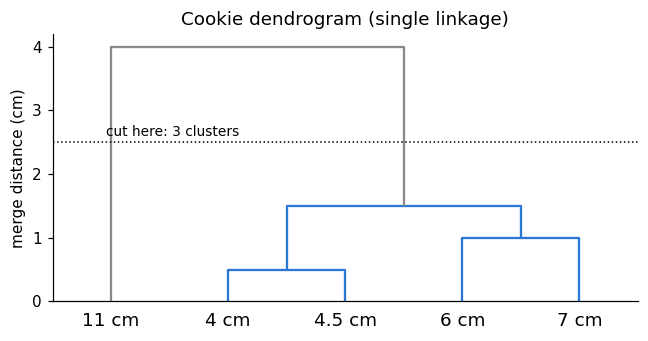

Cutting into 3 clusters: [1 1 2 2 3]


In [5]:
Xc = np.array(cookies, dtype=float).reshape(-1, 1)
L_single = linkage(Xc, method='single')
fig, ax = plt.subplots(figsize=(6, 3.2))
dendrogram(L_single, labels=[f'{c} cm' for c in cookies], ax=ax, color_threshold=2.5, above_threshold_color=GRAY)
ax.axhline(2.5, color='black', ls=':', lw=1); ax.text(4.6, 2.6, 'cut here: 3 clusters', fontsize=9)
ax.set_ylabel('merge distance (cm)'); ax.set_title('Cookie dendrogram (single linkage)'); ax.grid(False)
plt.tight_layout(); plt.show()
print('Cutting into 3 clusters:', fcluster(L_single, 3, 'maxclust'))

Cutting the tree anywhere between the merges at 1 cm and 1.5 cm gives three clusters: (4, 4.5), (6, 7) and (11). This is HAC's main convenience: the tree is built once, and any number of clusters can be read off it afterwards.

## 3. The four linkage methods
The linkage rule decides how the distance between two *clusters* is measured. For the clusters (4, 4.5) and (6, 7) from the reading:

In [6]:
a, b = [4, 4.5], [6, 7]
pair_d = [abs(x - y) for x in a for y in b]
merged = a + b
sse = lambda v: sum((x - np.mean(v)) ** 2 for x in v)
ward_increase = sse(merged) - sse(a) - sse(b)

pd.DataFrame({'rule': ['closest pair (4.5 to 6)', 'farthest pair (4 to 7)', f'mean of {pair_d}',
                       f'SSE after merge {sse(merged):.4f} minus SSE before {sse(a):.3f} + {sse(b):.3f}'],
              'distance': [min(pair_d), max(pair_d), np.mean(pair_d), ward_increase]},
             index=['single', 'complete', 'average', 'Ward (increase in SSE)']).round(4)

,rule,distance
single,closest pair (4.5 to 6),1.5000
complete,farthest pair (4 to 7),3.0000
average,"mean of [2, 3, 1.5, 2.5]",2.2500
Ward (increase in SSE),SSE after merge 5.6875 minus SSE before 0.125 ...,5.0625


These match the reading: single linkage 1.5, complete 3 and average 2.25. For **Ward's method**, the merge cost is the increase in the total within-cluster sum of squared errors (SSE): the merged cluster's SSE (5.6875) minus the SSE of the two clusters before merging (0.125 + 0.5), an increase of **5.0625**. Ward always makes the merge that increases total SSE the least. That is the same quantity k-means minimizes (WCSS), so Ward tends to produce compact, roughly round clusters like k-means does. (SciPy reports Ward heights on a different scale, $\sqrt{2 \times \text{increase}}$, but the merge order is the same.)

All four rules on the cookies:

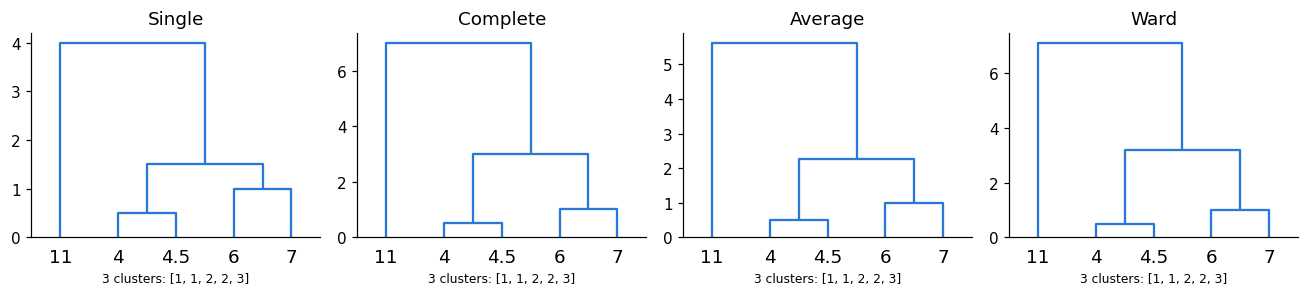

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=False)
for ax, m in zip(axes, ['single', 'complete', 'average', 'ward']):
    L = linkage(Xc, method=m)
    dendrogram(L, labels=[str(c) for c in cookies], ax=ax, color_threshold=0, above_threshold_color=BLUE)
    ax.set_title(m.capitalize()); ax.grid(False)
    ax.set_xlabel('3 clusters: ' + str(fcluster(L, 3, 'maxclust').tolist()), fontsize=8)
plt.tight_layout(); plt.show()

On five evenly spread cookies, all four rules give the same three clusters. They differ only in the heights at which merges happen. The differences appear when the data has shape or outliers.

## 4. Linkage methods on shaped data
Two interleaved half-moons and one tight blob, a standard test where the "right" answer is obvious to the eye but not to every algorithm. For comparison, k-means and DBSCAN are run on the same points.

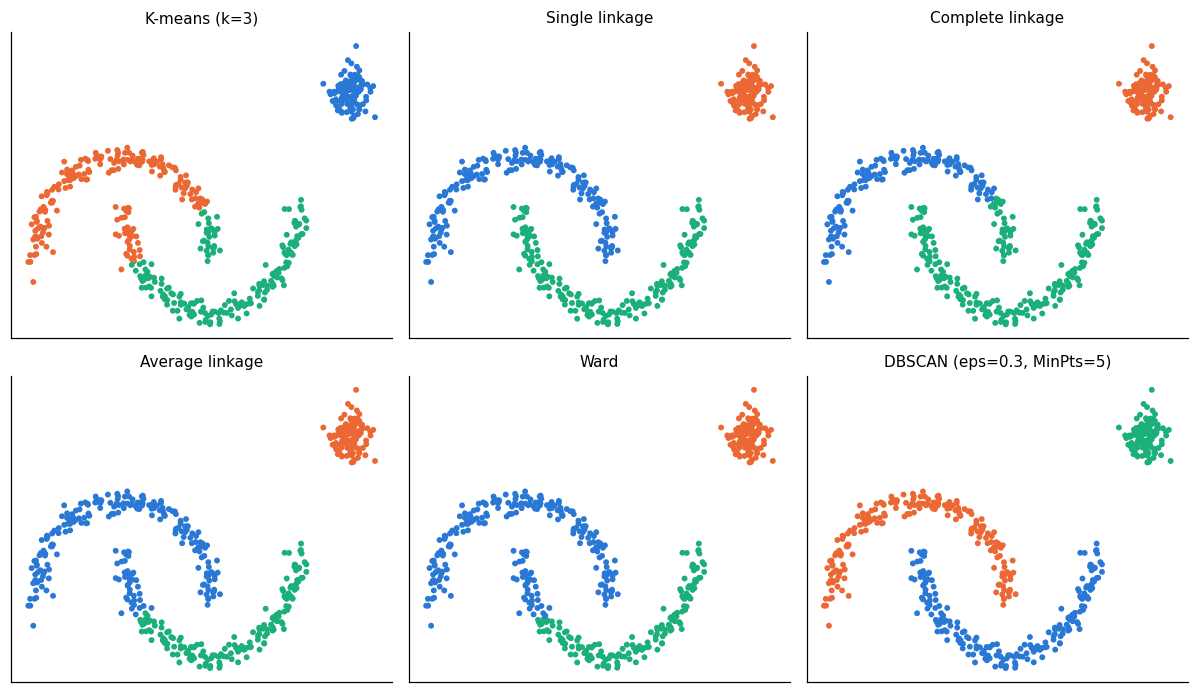

In [8]:
Xm, _ = make_moons(400, noise=0.06, random_state=SEED)
Xb_, _ = make_blobs(120, centers=[[2.6, 1.6]], cluster_std=0.12, random_state=SEED)
Xshape = StandardScaler().fit_transform(np.vstack([Xm, Xb_]))

models = {'K-means (k=3)': KMeans(3, n_init=10, random_state=SEED),
          'Single linkage': AgglomerativeClustering(3, linkage='single'),
          'Complete linkage': AgglomerativeClustering(3, linkage='complete'),
          'Average linkage': AgglomerativeClustering(3, linkage='average'),
          'Ward': AgglomerativeClustering(3, linkage='ward'),
          'DBSCAN (eps=0.3, MinPts=5)': DBSCAN(eps=0.3, min_samples=5)}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
for ax, (name, m) in zip(axes.ravel(), models.items()):
    lab = m.fit_predict(Xshape)
    cols = [GRAY if l == -1 else PAL[l % len(PAL)] for l in lab]
    ax.scatter(Xshape[:, 0], Xshape[:, 1], c=cols, s=8)
    extra = f' | noise: {(lab == -1).sum()}' if (lab == -1).any() else ''
    ax.set_title(f'{name}{extra}', fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

- **Single linkage** follows each moon along its length, because it only needs one close pair of points to join two clusters. That same property is its weakness: one stray point between two groups can chain them together, and on noisy data it often produces one giant cluster plus a few isolated points (Section 8 shows this on BRFSS).
- **Complete linkage** also separates the moons here, because the gap between them is wide relative to their size. It judges clusters by their farthest members, so with longer or closer shapes it tends to cut them into compact pieces of similar diameter.
- **Average linkage and Ward** both put the inner tip of the upper moon with the wrong group. Ward minimizes squared error, as k-means does, so both look for round clusters.
- **K-means** splits the two moons into a left half and a right half: its round clusters cannot follow a curved shape.
- **DBSCAN** recovers both moons and the blob without being told how many clusters to find, because it follows dense regions of any shape. (This example has no isolated points, so nothing is labeled noise; Section 5 adds some.)

The linkage rule is a built-in assumption about what a cluster looks like. Different rules on the same data can give very different answers, so the rule needs to fit the shape of the groups being looked for.

## 5. DBSCAN by hand: core, border and noise points
DBSCAN has two parameters:
- **ε (eps):** the neighborhood radius. Two points are neighbors if they are at most ε apart.
- **MinPts (`min_samples`):** the number of points, *including the point itself*, that must be within ε for a point to be a **core point**.

Every point is then one of three types:
- **Core:** at least MinPts points within ε.
- **Border:** fewer than MinPts points within ε, but within ε of a core point.
- **Noise:** neither.

A cluster is a set of core points that can be linked by steps of at most ε, plus the border points attached to them. Applied to the cookies with ε = 1 cm and MinPts = 2:

In [9]:
def point_types(X, eps, minpts):
    db = DBSCAN(eps=eps, min_samples=minpts).fit(X)
    kind = np.full(len(X), 'border', dtype=object)
    kind[db.core_sample_indices_] = 'core'; kind[db.labels_ == -1] = 'noise'
    nbrs = [int((np.abs(X - x).max(axis=1) <= eps).sum()) if X.shape[1] == 1 else None for x in X]
    return db.labels_, kind, nbrs

lab, kind, nbrs = point_types(Xc, eps=1.0, minpts=2)
pd.DataFrame({'diameter': cookies, 'points within 1 cm (incl. itself)': nbrs, 'type': kind, 'cluster': lab})

,diameter,points within 1 cm (incl. itself),type,cluster
0,4.0,2,core,0
1,4.5,2,core,0
2,6.0,2,core,1
3,7.0,2,core,1
4,11.0,1,noise,-1


The 4- and 4.5-cm cookies are neighbors of each other, so each has 2 points within 1 cm and both are core points; the same is true of 6 and 7. The 11-cm cookie has no neighbors and becomes noise rather than being forced into a cluster. Raising MinPts to 3 changes the picture:

In [10]:
for eps, mp in [(1.0, 3), (1.5, 3), (4.0, 2)]:
    lab, kind, nbrs = point_types(Xc, eps, mp)
    print(f'eps={eps}, MinPts={mp}: types={list(kind)}  clusters={[int(l) for l in lab]}')

eps=1.0, MinPts=3: types=['noise', 'noise', 'noise', 'noise', 'noise']  clusters=[-1, -1, -1, -1, -1]
eps=1.5, MinPts=3: types=['border', 'core', 'core', 'border', 'noise']  clusters=[0, 0, 0, 0, -1]
eps=4.0, MinPts=2: types=['core', 'core', 'core', 'core', 'core']  clusters=[0, 0, 0, 0, 0]


With MinPts = 3 and ε = 1, no cookie has enough neighbors, so **everything is noise**. Widening ε to 1.5 lets 4.5 and 6 each reach three points (4.5 reaches 4 and 6; 6 reaches 4.5 and 7), making them core points, while 4 and 7 become border points: one cluster of four plus the 11-cm cookie as noise. With ε = 4, the 11-cm cookie is within reach of 7 and **everything merges into one cluster**. These are the two failure modes from the reading: ε too small gives mostly noise, and ε too large merges everything.

On two-dimensional data, the three point types look like this:

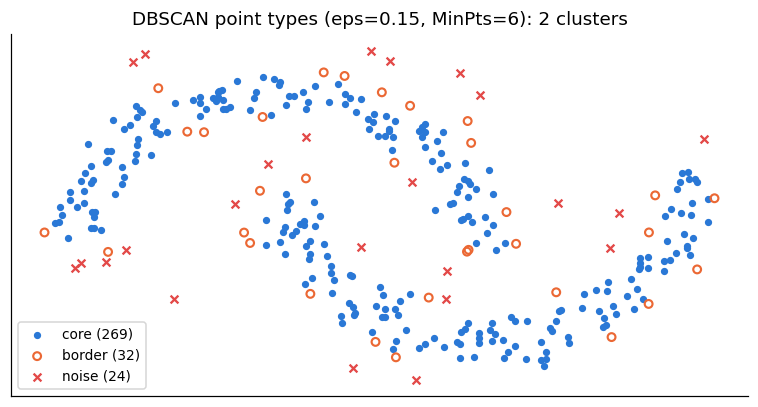

In [11]:
Xd, _ = make_moons(300, noise=0.09, random_state=1)
Xd = np.vstack([Xd, np.random.default_rng(1).uniform([-1.2, -0.8], [2.2, 1.3], (25, 2))])
db = DBSCAN(eps=0.15, min_samples=6).fit(Xd)
core = np.zeros(len(Xd), bool); core[db.core_sample_indices_] = True
noise = db.labels_ == -1; border = ~core & ~noise
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(*Xd[core].T, s=14, color=BLUE, label=f'core ({core.sum()})')
ax.scatter(*Xd[border].T, s=26, facecolors='none', edgecolors=ORANGE, lw=1.4, label=f'border ({border.sum()})')
ax.scatter(*Xd[noise].T, s=26, marker='x', color=RED, label=f'noise ({noise.sum()})')
ax.set_title(f'DBSCAN point types (eps=0.15, MinPts=6): {db.labels_.max() + 1} clusters'); ax.legend(loc='lower left', fontsize=9)
ax.set_xticks([]); ax.set_yticks([]); plt.tight_layout(); plt.show()

Core points fill the interior of each moon, border points sit along the thin edges, and the scattered background points are labeled noise. This is what makes DBSCAN robust to outliers: they never pull a cluster toward them, as they would pull a k-means centroid.

## 6. How ε and MinPts change the result
A sweep on the same moons-plus-noise data:

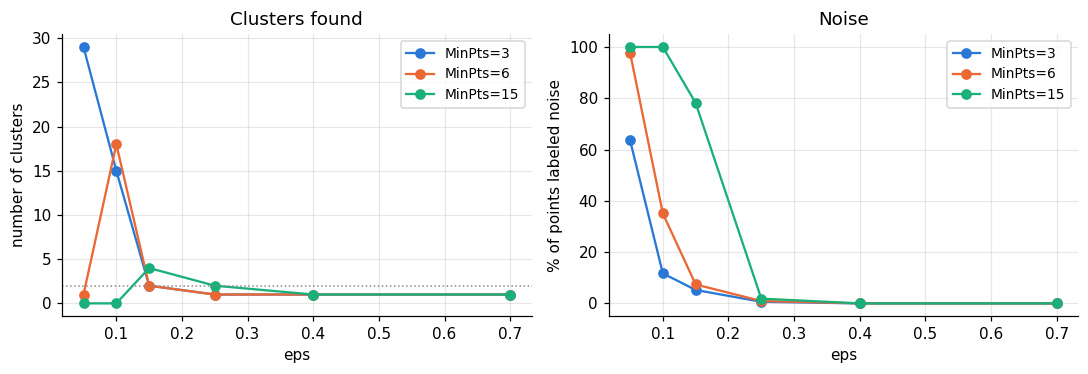

"clusters found, by MinPts",3,6,15
eps,,,
0.05,29,1,0
0.10,15,18,0
0.15,2,2,4
0.25,1,1,2
0.40,1,1,1
0.70,1,1,1


In [12]:
rows = []
for mp in [3, 6, 15]:
    for eps in [0.05, 0.1, 0.15, 0.25, 0.4, 0.7]:
        lab = DBSCAN(eps=eps, min_samples=mp).fit_predict(Xd)
        rows.append({'MinPts': mp, 'eps': eps, 'clusters': lab.max() + 1, 'noise %': (lab == -1).mean() * 100})
sweep = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for mp, c in zip([3, 6, 15], [BLUE, ORANGE, GREEN]):
    s = sweep[sweep.MinPts == mp]
    axes[0].plot(s.eps, s.clusters, marker='o', color=c, label=f'MinPts={mp}')
    axes[1].plot(s.eps, s['noise %'], marker='o', color=c, label=f'MinPts={mp}')
axes[0].axhline(2, color=GRAY, ls=':', lw=1); axes[0].set_ylabel('number of clusters'); axes[1].set_ylabel('% of points labeled noise')
for ax in axes: ax.set_xlabel('eps'); ax.legend(fontsize=9)
axes[0].set_title('Clusters found'); axes[1].set_title('Noise'); plt.tight_layout(); plt.show()
sweep.pivot(index='eps', columns='MinPts', values='clusters').rename_axis(columns='clusters found, by MinPts')

- **ε too small:** neighborhoods are nearly empty, most points are noise, and the few dense spots become many tiny clusters.
- **ε too large:** neighborhoods overlap across the gap between the moons and everything merges into one cluster.
- **MinPts** sets how dense a region must be. Larger values make the method stricter: more noise at a given ε, and a larger ε needed before anything forms (with MinPts = 15, no cluster appears until ε = 0.15).

There is a usable range of ε in between, and the **k-distance plot** finds it without trial and error: for every point, compute the distance to its MinPts-th nearest neighbor, sort those distances and plot them. Points inside dense regions have small k-distances and outliers have large ones, so a sharp bend (the "knee") marks a good ε.

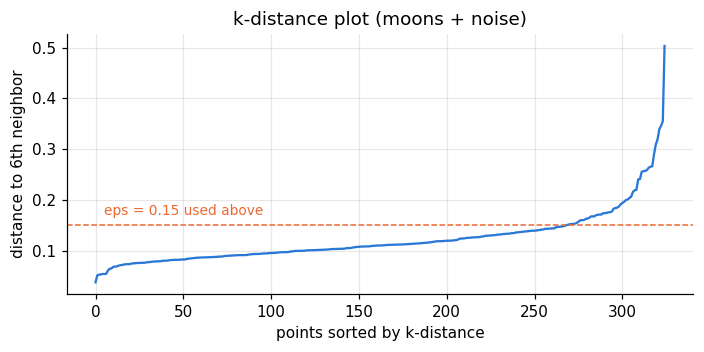

In [13]:
mp = 6
kd = np.sort(NearestNeighbors(n_neighbors=mp).fit(Xd).kneighbors(Xd)[0][:, -1])
fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.plot(kd, color=BLUE); ax.axhline(0.15, color=ORANGE, ls='--', lw=1); ax.text(5, 0.17, 'eps = 0.15 used above', color=ORANGE, fontsize=9)
ax.set_xlabel('points sorted by k-distance'); ax.set_ylabel(f'distance to {mp}th neighbor'); ax.set_title('k-distance plot (moons + noise)')
plt.tight_layout(); plt.show()

The curve is flat for the points inside the moons and rises sharply for the noise points. The knee sits near ε = 0.15, the value used in Section 5.

## 7. DBSCAN on the project data
### Choosing MinPts and ε
For data with more than two dimensions, a common rule of thumb is **MinPts = 2 × number of features** (Schubert et al., 2017): 42 for BRFSS and 28 for the Lifestyle data. I then read ε off each dataset's k-distance plot.

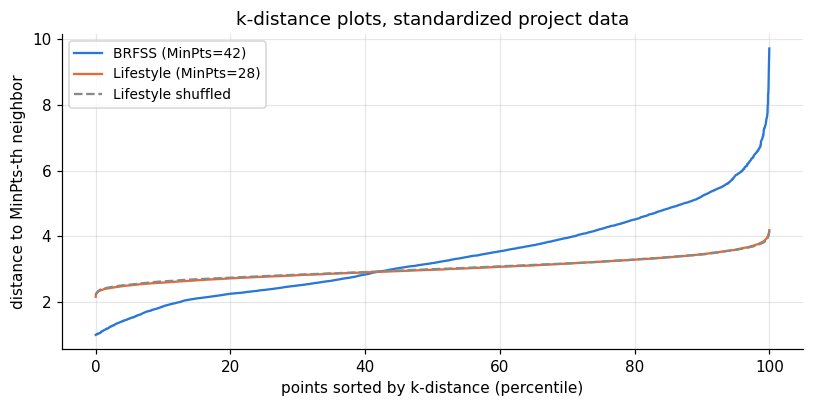

In [14]:
kdist = {}
for name in ['B', 'A', 'A_null']:
    z = S[name]; mp = 2 * z.shape[1]
    kdist[name] = np.sort(NearestNeighbors(n_neighbors=mp).fit(z).kneighbors(z)[0][:, -1])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for name, lab, c, ls in [('B', 'BRFSS (MinPts=42)', BLUE, '-'), ('A', 'Lifestyle (MinPts=28)', ORANGE, '-'), ('A_null', 'Lifestyle shuffled', GRAY, '--')]:
    ax.plot(np.linspace(0, 100, len(kdist[name])), kdist[name], color=c, ls=ls, label=lab)
ax.set_xlabel('points sorted by k-distance (percentile)'); ax.set_ylabel('distance to MinPts-th neighbor')
ax.set_title('k-distance plots, standardized project data'); ax.legend(fontsize=9); plt.tight_layout(); plt.show()

The two datasets look completely different:
- **Lifestyle:** the curve is nearly flat, rising only from about 2.4 to 3.9, and it lies exactly on its shuffled copy. Every point is about as isolated as every other: there are no dense regions and no gaps, so there is no knee to choose.
- **BRFSS:** the curve climbs steadily from about 1 to 7.5. Many respondents give very common answer patterns and sit in a dense core; others give unusual combinations and sit far from everyone. There is still no sharp knee, which suggests a gradient of density rather than separate groups.

With no single knee, I run DBSCAN across a range of ε values taken from percentiles of each k-distance curve (10th to 95th):

In [15]:
def dbscan_sweep(name):
    z = S[name]; mp = 2 * z.shape[1]; rows = []
    for e in np.percentile(kdist[name], [10, 25, 50, 75, 90, 95]):
        lab = DBSCAN(eps=e, min_samples=mp).fit_predict(z)
        nc = lab.max() + 1; noise = lab == -1
        row = {'eps': e, 'clusters': nc, 'noise %': noise.mean() * 100,
               'largest cluster': int(np.bincount(lab[~noise]).max()) if (~noise).any() else 0,
               'silhouette (non-noise)': silhouette_score(z[~noise], lab[~noise]) if nc > 1 else np.nan}
        if name == 'B':
            row['diabetes % (noise)'] = yS[noise].mean() * 100 if noise.any() else np.nan
            row['diabetes % (clustered)'] = yS[~noise].mean() * 100 if (~noise).any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index('eps')

t0 = time.time()
dbA, dbA_null, dbB = dbscan_sweep('A'), dbscan_sweep('A_null'), dbscan_sweep('B')
print(f'{time.time()-t0:.0f}s')
print('Lifestyle (real):'); display(dbA.round(3))
print('Lifestyle (shuffled):'); display(dbA_null.round(3))

6s
Lifestyle (real):


,clusters,noise %,largest cluster,silhouette (non-noise)
eps,,,,
2.582608,2,53.00,2210,0.055
2.762922,3,30.02,3422,0.021
2.974404,1,11.18,4441,NaN
3.219544,1,1.62,4919,NaN
3.448853,1,0.12,4994,NaN
3.584353,1,0.02,4999,NaN


Lifestyle (shuffled):


,clusters,noise %,largest cluster,silhouette (non-noise)
eps,,,,
2.617868,3,51.08,2363,0.028
2.779964,2,28.22,3561,0.047
2.994459,1,9.76,4512,NaN
3.219457,1,1.60,4920,NaN
3.442188,1,0.10,4995,NaN
3.580775,1,0.02,4999,NaN


On the Lifestyle data, DBSCAN behaves exactly as it does on the shuffled copy: at small ε most points are noise and the rest form one to three loose groups (silhouette 0.02–0.06), and from the median ε upward everything is one cluster. That is DBSCAN's signature for data with uniform density: there is nothing to separate.

In [16]:
dbB.round(3)

,clusters,noise %,largest cluster,silhouette (non-noise),diabetes % (noise),diabetes % (clustered)
eps,,,,,,
1.853835,10,79.08,295,0.270,18.918,6.597
2.358681,1,61.84,1908,NaN,20.246,10.010
3.178571,3,33.58,3142,0.190,24.122,12.406
4.215294,4,12.16,4001,0.223,28.947,14.595
5.220714,2,3.12,4718,0.245,30.769,15.875
5.856999,1,1.04,4948,NaN,21.154,16.289


On BRFSS, DBSCAN never splits the data into well-separated groups either. At the smallest ε it finds ten small dense pockets and calls 79% of respondents noise; from there up, it finds one dense core plus at most a few small pieces, and the core grows as ε increases. But the **noise label is informative**:

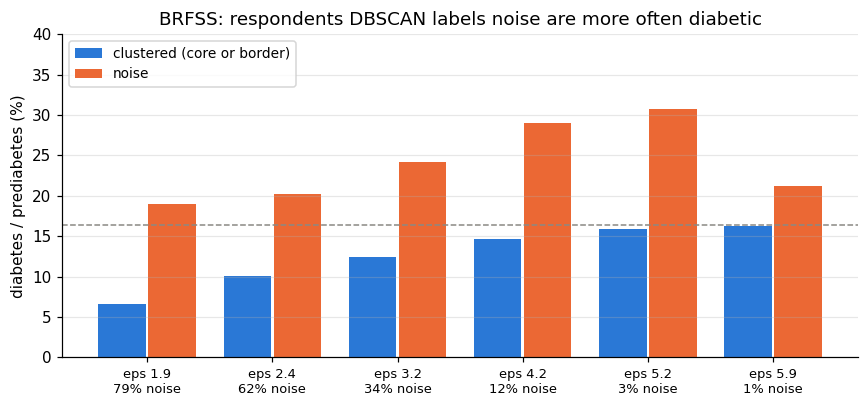

Ratio noise / clustered: [2.87, 2.02, 1.94, 1.98, 1.94, 1.3]


In [17]:
d = dbB.dropna(subset=['diabetes % (noise)'])
x = np.arange(len(d)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - w / 2 - 0.01, d['diabetes % (clustered)'], w, color=BLUE, label='clustered (core or border)')
ax.bar(x + w / 2 + 0.01, d['diabetes % (noise)'], w, color=ORANGE, label='noise')
ax.set_xticks(x, [f'eps {e:.1f}\n{p:.0f}% noise' for e, p in zip(d.index, d['noise %'])], fontsize=8.5)
ax.axhline(yS.mean() * 100, color=GRAY, ls='--', lw=1)
ax.set_ylabel('diabetes / prediabetes (%)'); ax.set_ylim(0, 40); ax.legend(loc='upper left', fontsize=9)
ax.set_title('BRFSS: respondents DBSCAN labels noise are more often diabetic'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print('Ratio noise / clustered:', (d['diabetes % (noise)'] / d['diabetes % (clustered)']).round(2).tolist())

At every ε, respondents labeled noise are **1.3 to 2.9 times** as likely to have diabetes or prediabetes as respondents inside clusters, even though diabetes played no part in the clustering. A "noise" point is a respondent whose combination of answers is unusual, and in health survey data, unusual answer combinations tend to be worse health profiles. For a screening program, DBSCAN's noise label works as a simple **atypical-profile flag**.

At a very small ε, DBSCAN picks out the opposite end: tiny clusters of nearly identical respondents.

In [18]:
lab = DBSCAN(eps=0.5, min_samples=10).fit_predict(S['B'])
core = lab != -1
print(f'eps=0.5, MinPts=10: {lab.max() + 1} micro-clusters, {core.sum()} respondents ({core.mean():.1%}); noise {(~core).mean():.1%}')
print(f'Diabetes: {yS[core].mean():.1%} in micro-clusters vs. {yS[~core].mean():.1%} in noise')
print('Exact duplicate rows in the full BRFSS file:', brfss.drop(columns='diabetes').duplicated().sum())

eps=0.5, MinPts=10: 3 micro-clusters, 59 respondents (1.2%); noise 98.8%
Diabetes: 3.4% in micro-clusters vs. 16.5% in noise
Exact duplicate rows in the full BRFSS file: 23899


These micro-clusters are small groups of respondents who gave nearly the same answers to all 21 questions, and only 3.4% of them are diabetic. BRFSS contains 23,899 exact duplicate rows; repeated common answer patterns like these are what make such tiny, very dense pockets possible.

## 8. HAC on the project data
I build the full tree with all four linkage methods on each 5,000-row sample and compare:
- **Cophenetic correlation:** how well the tree's merge heights preserve the original pairwise distances (1 = perfectly).
- **Silhouette** at 2–8 clusters.
- **Cluster sizes** when the tree is cut into 3 clusters, since a high silhouette with one giant cluster is not useful.

In [19]:
links, rows = {}, []
t0 = time.time()
for name in ['B', 'A', 'A_null']:
    z = S[name]; dz = pdist(z)
    for m in ['ward', 'complete', 'average', 'single']:
        L = linkage(z, method=m); links[(name, m)] = L
        sils = [silhouette_score(z, fcluster(L, k, 'maxclust')) for k in range(2, 9)]
        rows.append({'data': name, 'linkage': m, 'cophenetic r': cophenet(L, dz)[0],
                     'silhouette k=2': sils[0], 'silhouette k=3': sils[1], 'best silhouette (k=2-8)': max(sils),
                     'sizes at k=3': sorted(np.bincount(fcluster(L, 3, 'maxclust'))[1:].tolist(), reverse=True)})
print(f'{time.time()-t0:.0f}s')
hac = pd.DataFrame(rows).set_index(['data', 'linkage'])
hac.round(3)

21s


cophenetic r  silhouette k=2  silhouette k=3  \
data   linkage                                                  
B      ward             0.586           0.156           0.161   
       complete         0.735           0.423           0.220   
       average          0.853           0.465           0.428   
       single           0.808           0.465           0.454   
A      ward             0.410           0.107           0.082   
       complete         0.181           0.013          -0.002   
       average          0.457           0.133           0.075   
       single           0.452           0.153           0.087   
A_null ward             0.404           0.104           0.084   
       complete         0.181           0.011           0.003   
       average          0.454           0.107           0.038   
       single           0.440           0.107           0.067   

                 best silhouette (k=2-8)       sizes at k=3  
data   linkage                                               
B      ward                        0.186  [3120, 1498, 382]  
       complete                    0.423    [4367, 619, 14]  
       average                     0.465      [4987, 12, 1]  
       single                      0.465       [4998, 1, 1]  
A      ward                        0.107  [2919, 1087, 994]  
       complete                    0.013  [3154, 1218, 628]  
       average                     0.133       [4997, 2, 1]  
       single                      0.153       [4998, 1, 1]  
A_null ward                        0.104  [2904, 1133, 963]  
       complete                    0.011  [3037, 1034, 929]  
       average                     0.107       [4996, 3, 1]  
       single                      0.107       [4997, 2, 1]

**BRFSS.** Average and single linkage have the highest silhouettes (0.47) and the highest cophenetic correlations, but their "clusters" are useless: cut into three, they give about 4,990 respondents in one cluster and a handful in the others. This is the chaining described in Section 4. Rare answer combinations sit far from everyone, so they are the last points to join, and they end up as tiny clusters of their own. Complete linkage is somewhat better balanced but still lopsided. **Ward** gives balanced clusters (3,120 / 1,498 / 382). Its silhouette is lower because the groups overlap, but they are the only ones of the four that describe a real share of the population.

**Lifestyle.** All four methods behave almost identically on the real and shuffled data, the same pattern as k-means and DBSCAN, confirming there is no structure to find.

Silhouette alone would pick the worst clustering here. It has to be read together with cluster sizes.

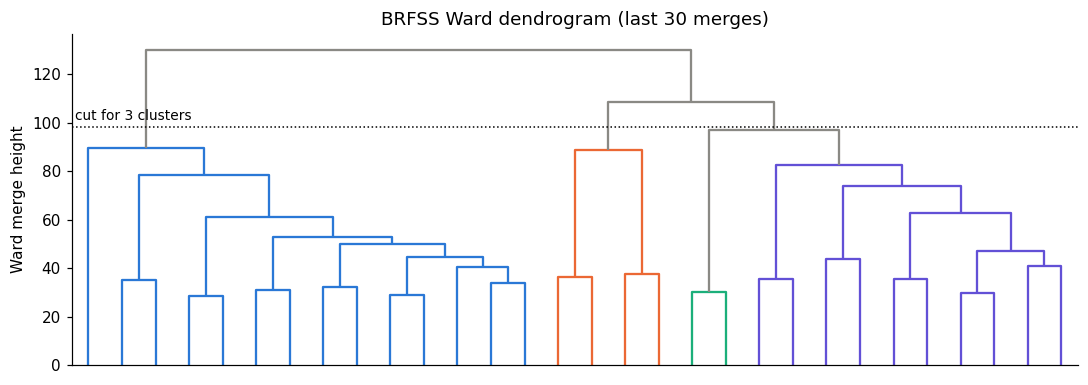

In [20]:
L = links[('B', 'ward')]
fig, ax = plt.subplots(figsize=(10, 3.6))
dendrogram(L, truncate_mode='lastp', p=30, ax=ax, color_threshold=L[-3, 2], above_threshold_color=GRAY, no_labels=True)
ax.axhline(L[-3, 2] + 1, color='black', ls=':', lw=1); ax.text(1, L[-3, 2] + 4, 'cut for 3 clusters', fontsize=9)
ax.set_ylabel('Ward merge height'); ax.set_title('BRFSS Ward dendrogram (last 30 merges)'); ax.grid(False)
plt.tight_layout(); plt.show()

The tall vertical gaps near the top of the tree mean the last few merges join groups that are clearly different. Cutting below them gives three clusters. Do they mean anything for diabetes, and do they agree with Week 10's k-means?

In [21]:
ward3 = fcluster(links[('B', 'ward')], 3, 'maxclust')
prof_cols = ['GenHlth', 'PhysHlth', 'DiffWalk', 'BMI', 'HighBP', 'HighChol', 'Age', 'Income', 'AnyHealthcare', 'CholCheck']
Bs = B.iloc[idxB].reset_index(drop=True)
prof = Bs.groupby(ward3)[prof_cols].mean()
prof.insert(0, 'diabetes (held out)', pd.Series(yS).groupby(ward3).mean())
prof.insert(0, 'size', np.bincount(ward3)[1:])
display(prof.rename_axis('Ward cluster').round(2))

km3B = KMeans(3, n_init=10, random_state=SEED).fit_predict(S['B'])
km3A = KMeans(3, n_init=10, random_state=SEED).fit_predict(S['A'])
print(f"Agreement with k-means (k=3), adjusted Rand index: BRFSS {adjusted_rand_score(ward3, km3B):.2f}, "
      f"Lifestyle {adjusted_rand_score(fcluster(links[('A', 'ward')], 3, 'maxclust'), km3A):.2f}")

,size,diabetes (held out),GenHlth,PhysHlth,DiffWalk,BMI,HighBP,HighChol,Age,Income,AnyHealthcare,CholCheck
Ward cluster,,,,,,,,,,,,
1,3120,0.12,2.18,1.14,0.01,27.53,0.38,0.39,7.92,6.56,1.00,1.00
2,382,0.11,2.70,4.11,0.16,28.24,0.25,0.29,6.44,5.23,0.34,0.57
3,1498,0.27,3.25,10.88,0.51,30.37,0.59,0.54,8.90,5.15,1.00,1.00


Agreement with k-means (k=3), adjusted Rand index: BRFSS 0.51, Lifestyle 0.33


The 382-member cluster is the rare-answer group: only 34% have health coverage and 57% had a cholesterol check. The 1,498-member Ward cluster is the poor-health group seen in Week 10: worse self-rated health, many more bad physical-health days, much more difficulty walking. Its diabetes rate is **27.2%**, against 11.8% and 10.7% in the other two clusters. Ward and k-means agree moderately on BRFSS (ARI 0.51), much more than on the Lifestyle data (0.33). Two different algorithms independently finding similar BRFSS groups is further evidence that those groups are real.

**DBSCAN or HAC?** On this project, each answered a different question:
- **HAC (Ward)** produced a full hierarchy of balanced segments, at any number of clusters, without fixing *k* in advance. It suits data like BRFSS, where groups overlap and differ in degree rather than being separated by gaps. Its costs are memory and time that grow with the square of the sample size, and the need to pick the linkage rule carefully.
- **DBSCAN** did not find separated segments because BRFSS has none, but it was the only method that **flags individuals** as atypical, and those flags carried real risk information. It suits data with dense groups separated by sparse regions, clusters of irregular shape, or a need to isolate outliers. It is sensitive to ε and MinPts, and it struggles when density varies smoothly, as it does here.

## 9. Summary
| Topic | Finding |
|---|---|
| HAC by hand | Reproduced the cookie merges (0.5, 1, 1.5, 4 cm); cutting at 3 clusters gives (4, 4.5), (6, 7), (11). |
| Linkage rules | Single 1.5, complete 3, average 2.25, Ward SSE increase 5.0625 for (4, 4.5) vs. (6, 7). On shaped data, single linkage follows the moons, Ward and k-means split them, DBSCAN recovers them. |
| DBSCAN by hand | Cookies with ε = 1, MinPts = 2: two clusters and 11 cm as noise. ε too small gives all noise; ε too large merges everything. |
| ε and MinPts | Larger MinPts makes DBSCAN stricter; the k-distance plot's knee picks ε. |
| Lifestyle data | Flat k-distance curve identical to its shuffled copy; DBSCAN and all four linkages behave the same on real and shuffled data. No structure. |
| BRFSS, DBSCAN | No separated clusters (density changes gradually), but noise points are 1.3–2.9 times as likely to be diabetic as clustered points. |
| BRFSS, HAC | Average and single linkage have the best silhouette (0.47) but chain into one giant cluster. Ward gives balanced clusters, including a poor-health cluster with 27.2% diabetes; it agrees with k-means (ARI 0.51). |

**Sources:** Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of KDD-96*, 226–231; Schubert, E., Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (2017). DBSCAN revisited, revisited: Why and how you should (still) use DBSCAN. *ACM Transactions on Database Systems, 42*(3); Hastie, Tibshirani & Friedman (2009), *The Elements of Statistical Learning*, Ch. 14.3; scikit-learn User Guide, *Clustering: DBSCAN and Hierarchical clustering* (https://scikit-learn.org/stable/modules/clustering.html).